In [1]:
def read_adds_muls(file):
    with open("../../data/results/" + file, 'r+') as f:
        all_lines = f.readlines()
    adds = []
    muls = []
    for line in all_lines:
        if "Additions" in line:
            vals = line.split(" ")
            adds.append(int(vals[1]))
            muls.append(int(vals[3]))
    return sum(adds), sum(muls)

In [2]:
#GHZ
#dense
def get_add_mul_lists(circ, version):
    add_values = []
    mul_values = []
    for q in ["3", "4", "5", "6", "7", "8", "9"]:
        adds, muls = read_adds_muls(circ + q + version)
        add_values.append(adds)
        mul_values.append(muls)
    return add_values, mul_values

In [3]:
y1, z1 = get_add_mul_lists("ghz", "dense")
y1new = [x + y for x, y in zip(y1, z1)]
y2, z2 = get_add_mul_lists("ghz", "sparse")
y2new = [x + y for x, y in zip(y2, z2)]

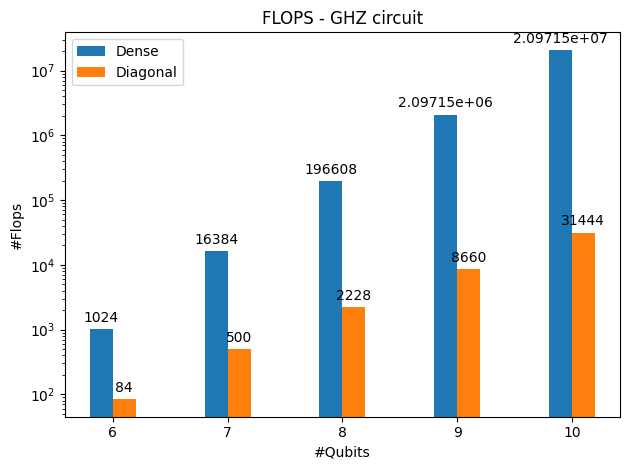

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import math

labels = ["6", "7", "8", "9", "10"]

x = np.arange(len(labels))  # the label locations
width = 0.2  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, y1new[:5], width, label='Dense')
rects2 = ax.bar(x + width/2, y2new[:5], width, label='Diagonal')

ax.set_yscale('log')
ax.set_ylabel('#Flops')
ax.set_xlabel('#Qubits')
ax.set_title('FLOPS - GHZ circuit')
ax.set_xticks(x, labels)
ax.legend()

ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

fig.tight_layout()

plt.show()

In [5]:
y3, z3 = get_add_mul_lists("ham", "dense")
y3new = [x + y for x, y in zip(y3, z3)]
y4, z4 = get_add_mul_lists("ham", "sparse")
y4new = [x + y for x, y in zip(y4, z4)]

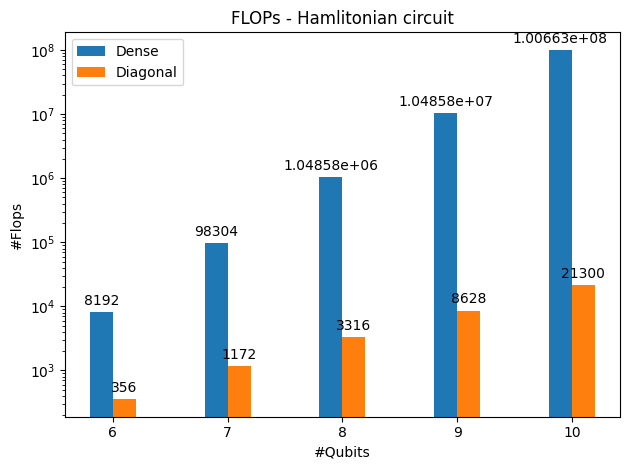

In [6]:
import matplotlib.pyplot as plt
import numpy as np


labels = ["6", "7", "8", "9", "10"]

x = np.arange(len(labels))  # the label locations
width = 0.2  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, y3new[:5], width, label='Dense')
rects2 = ax.bar(x + width/2, y4new[:5], width, label='Diagonal')

ax.set_yscale('log')
ax.set_ylabel('#Flops')
ax.set_xlabel('#Qubits')
ax.set_title('FLOPs - Hamlitonian circuit')
ax.set_xticks(x, labels)
ax.legend()

ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

fig.tight_layout()

plt.show()

In [7]:
y5, z5 = get_add_mul_lists("mermin_bell", "dense")
y5new = [x + y for x, y in zip(y5, z5)]
y6, z6 = get_add_mul_lists("mermin_bell", "sparse")
y6new = [x + y for x, y in zip(y6, z6)]

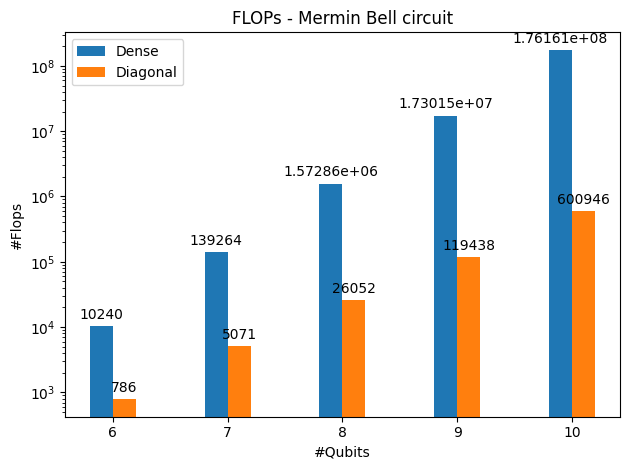

In [8]:
import math

labels = ["6", "7", "8", "9", "10"]

x = np.arange(len(labels))  # the label locations
width = 0.2  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, y5new[:5], width, label='Dense')
rects2 = ax.bar(x + width/2, y6new[:5], width, label='Diagonal')

ax.set_yscale('log')
ax.set_ylabel('#Flops')
ax.set_xlabel('#Qubits')
ax.set_title('FLOPs - Mermin Bell circuit')
ax.set_xticks(x, labels)
ax.legend()

ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

fig.tight_layout()
plt.show()

In [9]:
y7, z7 = read_adds_muls("vqeprep4dense")
y7new = y7 + z7
y8, z8 = read_adds_muls("vqeprep4sparse")
y8new = y8 + z8

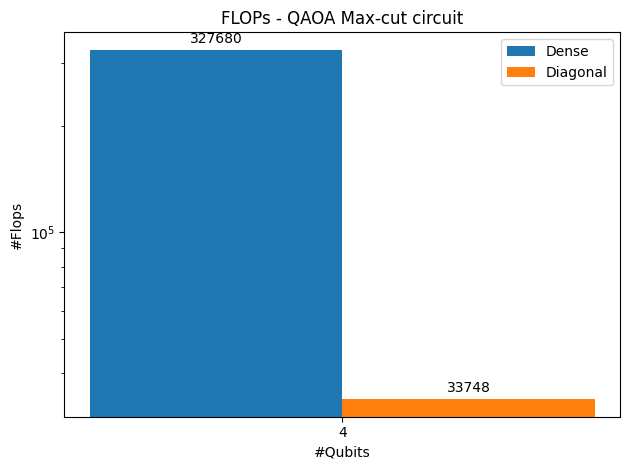

In [10]:
import math

labels = ["4"]

x = np.arange(len(labels))  # the label locations
width = 0.2  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, [y7new], width, label='Dense')
rects2 = ax.bar(x + width/2, [y8new], width, label='Diagonal')

ax.set_yscale('log')
ax.set_ylabel('#Flops')
ax.set_xlabel('#Qubits')
ax.set_title('FLOPs - QAOA Max-cut circuit')
ax.set_xticks(x, labels)
ax.legend()

ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

fig.tight_layout()
plt.show()

In [11]:
def get_add_mul_lists_suitesparse(version):
    add_values = []
    mul_values = []
    for num in [200, 600, 1000, 1400, 1800, 2200, 2500]:
        adds, muls = read_adds_muls("cryg" + str(num) + version)
        add_values.append(adds)
        mul_values.append(muls)
    return add_values, mul_values

y1, z1 = get_add_mul_lists_suitesparse("dense")
y1new = [x + y for x, y in zip(y1, z1)]
y2, z2 = get_add_mul_lists_suitesparse("sparse")
y2new = [x + y for x, y in zip(y2, z2)]

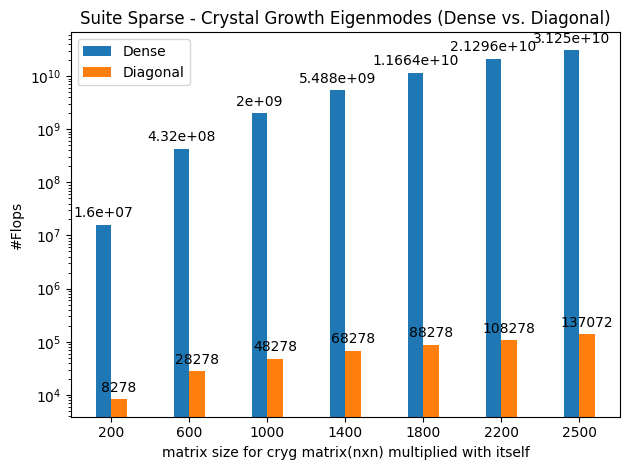

In [16]:
import math

labels = ["200", "600", "1000", "1400", "1800", "2200", "2500"]

x = np.arange(len(labels))  # the label locations
width = 0.2  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, y1new, width, label='Dense')
rects2 = ax.bar(x + width/2, y2new, width, label='Diagonal')

ax.set_yscale('log')
ax.set_ylabel('#Flops')
ax.set_xlabel('matrix size for cryg matrix(nxn) multiplied with itself')
ax.set_title('Suite Sparse - Crystal Growth Eigenmodes (Dense vs. Diagonal)')
ax.set_xticks(x, labels)
ax.legend()

ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

fig.tight_layout()
plt.show()

In [17]:
y11, z11 = read_adds_muls("ham9sparse")
y11new = y11 + z11
y12, z12 = read_adds_muls("shortham9sparse")
y12new = y12 + z12

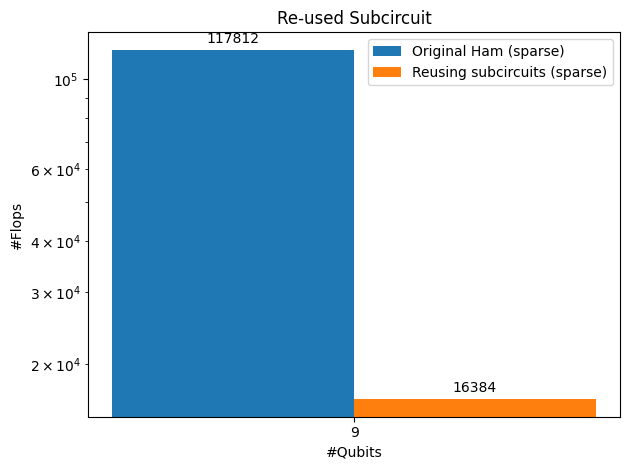

In [18]:
import math
import matplotlib.pyplot as plt
import numpy as np

labels = ["9"]

x = np.arange(len(labels))  # the label locations
width = 0.5  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, [y11new], width, label='Original Ham (sparse)')
rects2 = ax.bar(x + width/2, [y12new], width, label='Reusing subcircuits (sparse)')

ax.set_yscale('log')
ax.set_ylabel('#Flops')
ax.set_xlabel('#Qubits')
ax.set_title('Re-used Subcircuit')
ax.set_xticks(x, labels)
ax.legend()

ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

fig.tight_layout()
plt.show()